Plot the publication figures using the data generated in `generate_results.ipynb`. Run the corresponding generation cells first; the extended figure requires all four extended result files.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from itertools import cycle
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.patches as patches
from matplotlib.patches import ConnectionPatch
from config import results_loc


In [2]:
mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    'mathtext.fontset':   'cm'
})


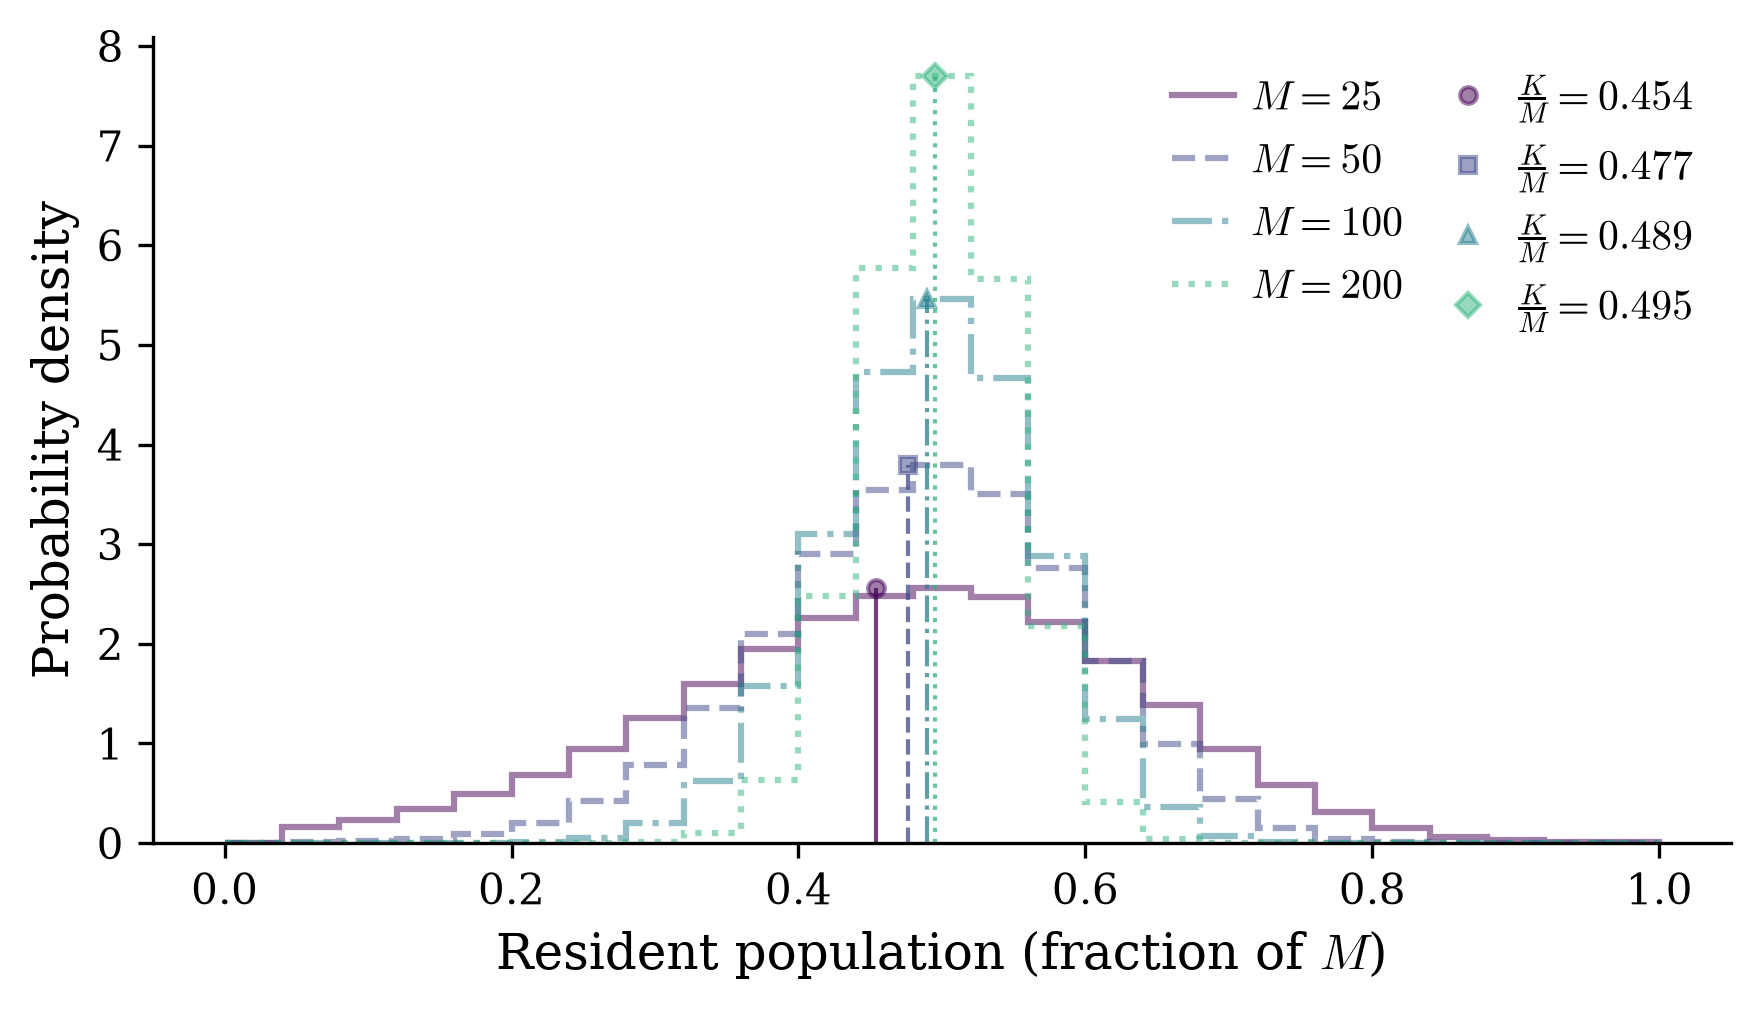

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "mathtext.fontset": "cm",
    "axes.linewidth": 0.8,
})

Ms = [25, 50,100, 200]
d = 0.5
linestyles = cycle(["-", "--", "-.", ":", (0, (3, 1, 1, 1))])
colors = plt.cm.viridis(np.linspace(0, 0.65, len(Ms)))
fig, ax = plt.subplots(figsize=(6, 3.5))

n_bins = 25
bin_edges = np.linspace(0, 1, n_bins + 1)
bin_width = bin_edges[1] - bin_edges[0]
markers = cycle(["o", "s", "^", "D", "v"])

for M, c in zip(Ms, colors):
    with np.load(results_loc / f"qsd_M{M}_d{d}.npz") as data:
        stationary_vec = data["distribution"]
    x = np.arange(1, M + 1) / M

    counts, _ = np.histogram(x, bins=bin_edges, weights=stationary_vec)
    density = counts / bin_width
    mean_x = np.sum(x * stationary_vec) / np.sum(stationary_vec)*M
    temp_linestyle = next(linestyles)
    ax.stairs(density, bin_edges, color=c, linestyle=temp_linestyle,
              linewidth=1.5, label=rf"$M={M}$",alpha=0.5)

    markerline, stemlines, _ = ax.stem(
            mean_x/M, max(density),
            linefmt="-", markerfmt=next(markers), basefmt=" "
        )
    plt.setp(markerline, color=c, markersize=4, markerfacecolor=c, markeredgecolor=c,alpha=0.5,label=fr"$\frac{{K}}{{M}}={mean_x/M:.3f}$")
    plt.setp(stemlines, color=c, linewidth=1.0, alpha=0.75, linestyle=temp_linestyle)

ax.set_xlabel("Resident population (fraction of $M$)")

ax.set_ylabel("Probability density")
handles, labels = ax.get_legend_handles_labels()
order = [0,2,4,6,1,3,5,7]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    frameon=False,
    loc="best",
    ncols=2,
    columnspacing=0.8,
    handlelength=1.5,
    handletextpad=0.4,
    alignment="left",
)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("qsd_by_M_hist.pdf", dpi=300)
plt.show()


/var/folders/x8/t754zhz129jg7vydskwt7htm0000gq/T/ipykernel_74122/81206786.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


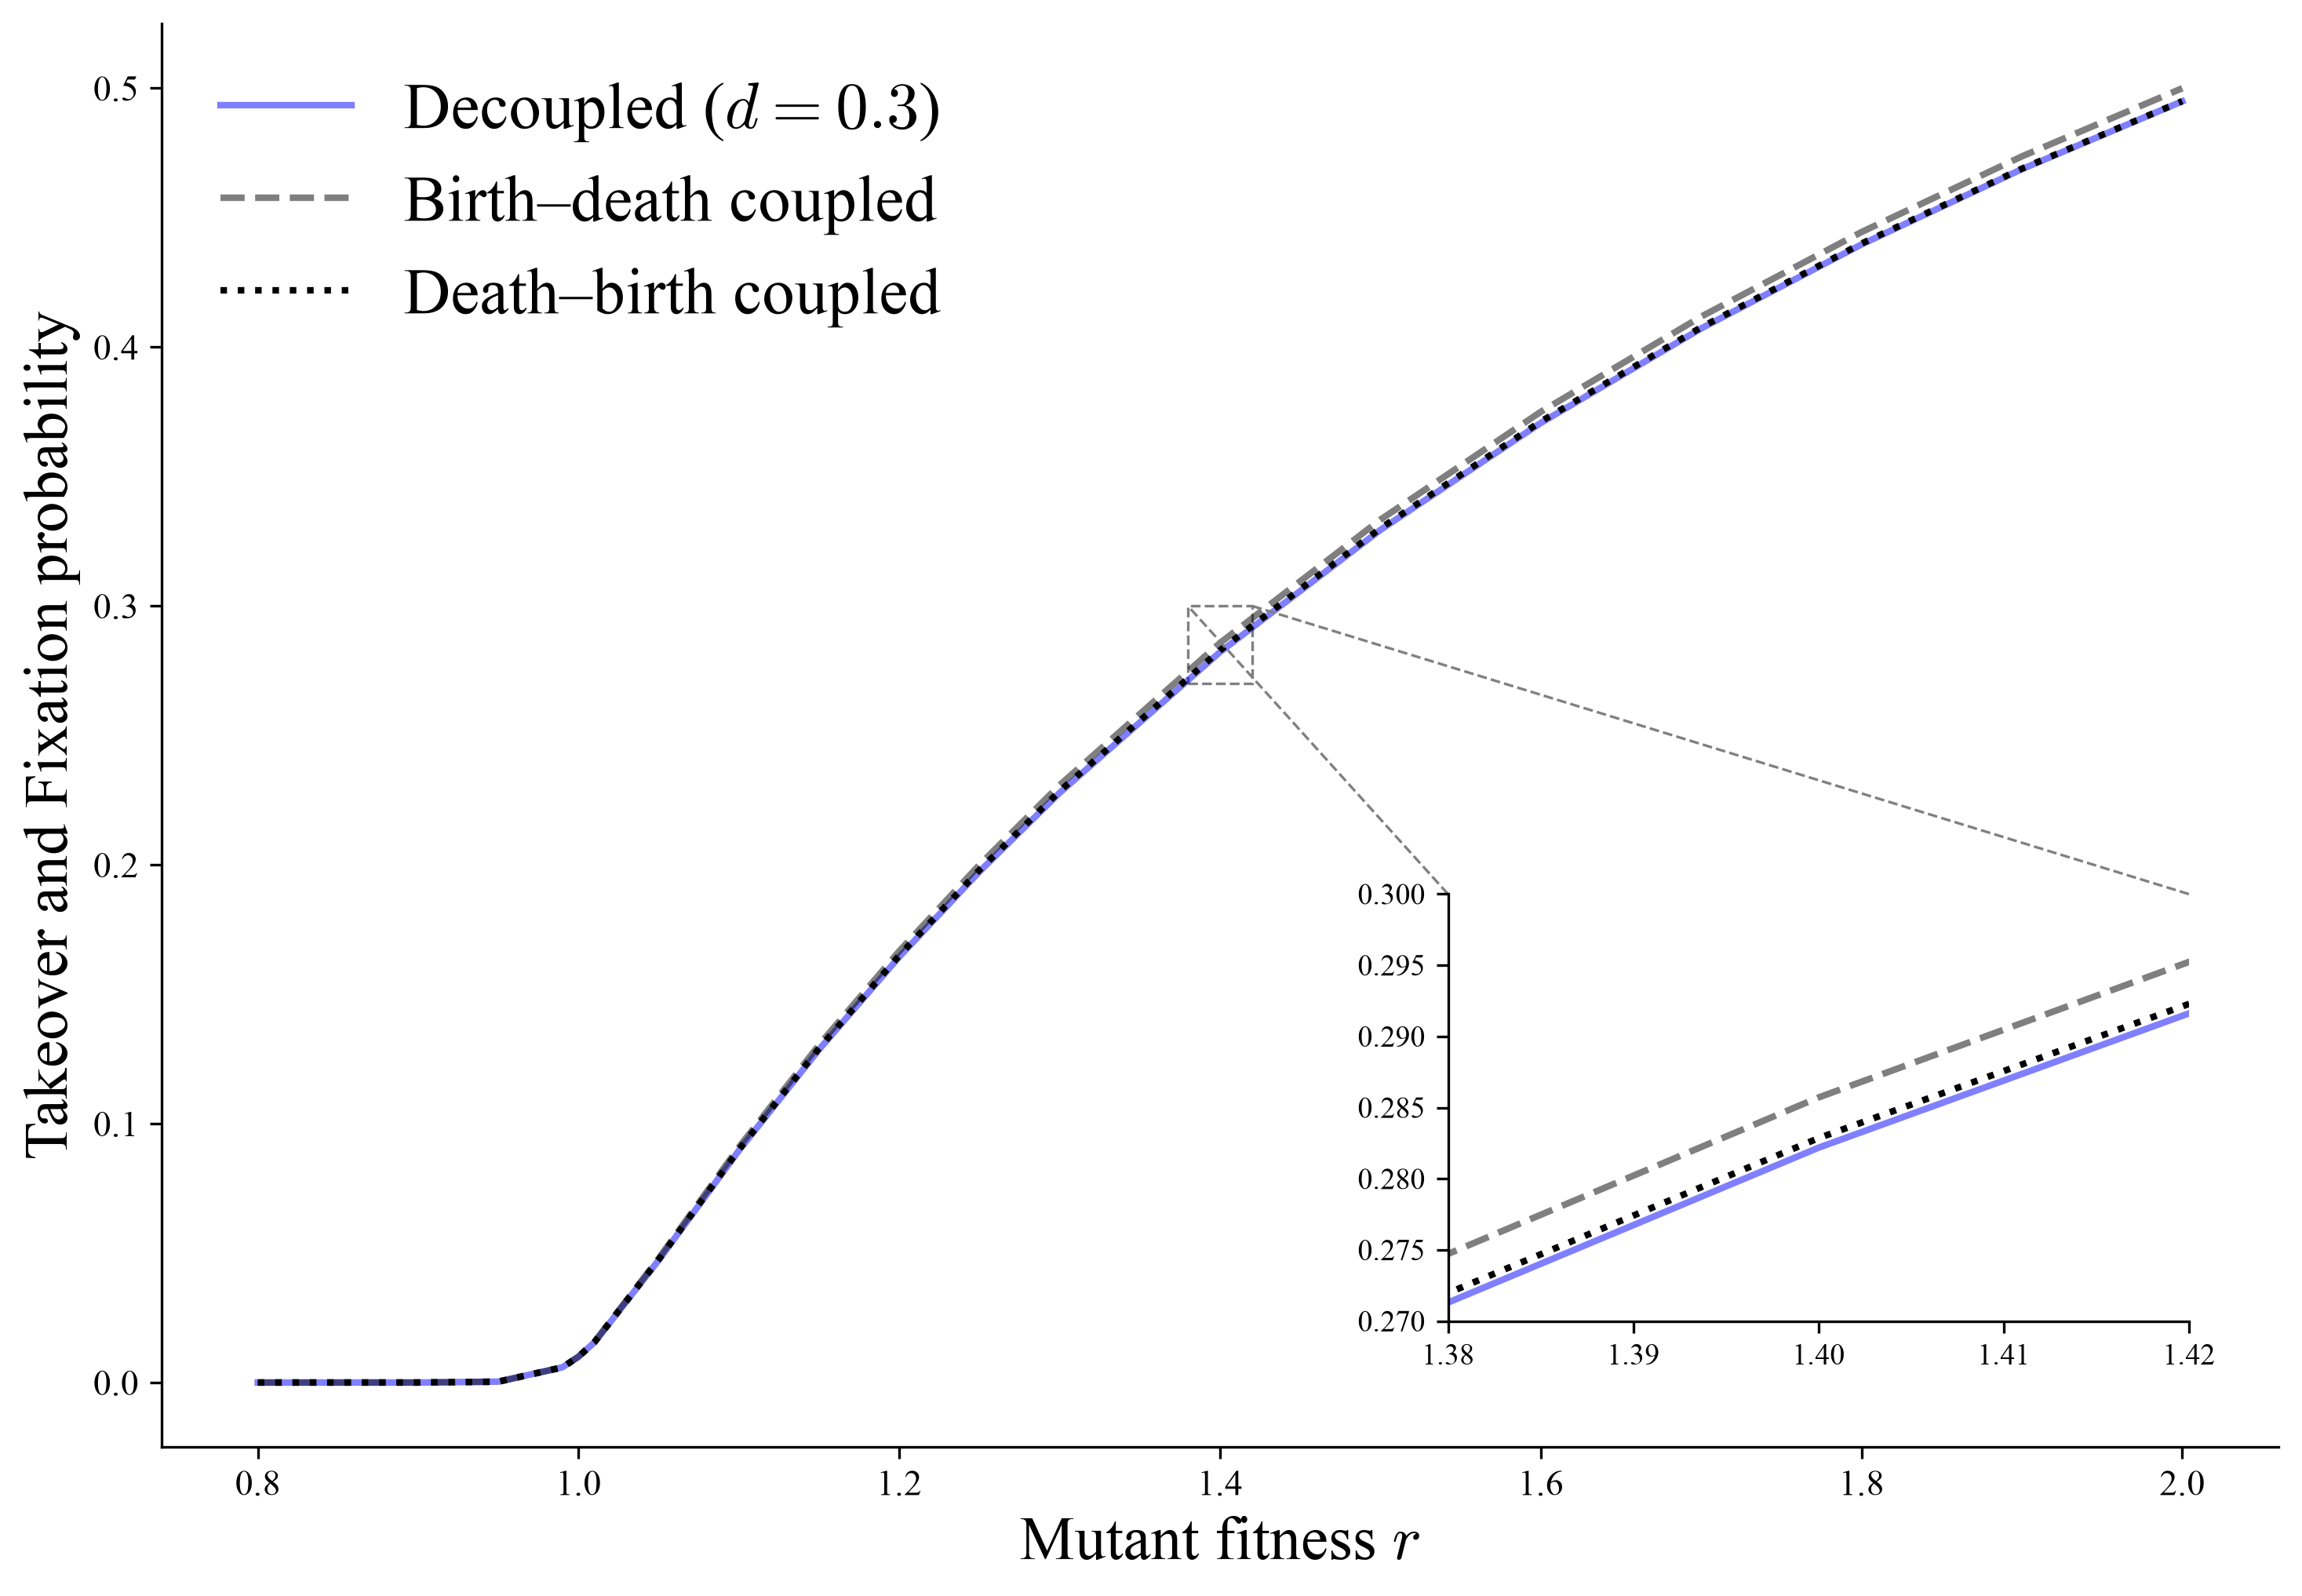

In [4]:
with np.load(results_loc / "well_mixed_standard_d0.3.npz") as data:
    rs = data["rs"]
    K = int(data["K"])
    all_well_mixed_fix_probs = {0.3: data["probabilities"]}

fig, ax = plt.subplots(figsize=(10, 7))
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.linewidth": 0.8
})

line_styles = ['-', '--', '-.', ':']

for idx, d in enumerate([0.3]):
    well_mixed_fix_probs = all_well_mixed_fix_probs[d]
    ax.plot(
        rs,
        well_mixed_fix_probs,
        color='blue',
        linestyle=line_styles[idx % len(line_styles)],
        linewidth=2,
        label=rf"Decoupled ($d={d}$)",
        alpha=0.5
    )

bd = [(1-1/r)/(1-1/r**K) if r!=1 else 1/K for r in rs]
ax.plot(rs, bd, color='black', linestyle='--', linewidth=2, label="Birth–death coupled", alpha=0.5)

db = [(1-1/K)*(1-1/r)/(1-1/r**(K-1)) if r!=1 else 1/K for r in rs]
ax.plot(rs, db, color='black', linestyle=':', linewidth=2, label="Death–birth coupled", alpha=1)

ax.set_xlabel(r"Mutant fitness $r$", fontsize=19)
ax.set_ylabel("Takeover and Fixation probability", fontsize=19)
ax.legend(frameon=False, fontsize=20)
ax.tick_params(labelsize=11)

x1, x2, y1, y2 = 1.38, 1.42, 0.27, 0.30

axins = inset_axes(ax, width="35%", height="30%", loc="upper left",
                   bbox_to_anchor=(0.6, -0.6, 1, 1),
                   bbox_transform=ax.transAxes)

for idx, d in enumerate([0.3]):
    axins.plot(rs, all_well_mixed_fix_probs[d],
               color='blue', linestyle=line_styles[idx % len(line_styles)],
               linewidth=2, alpha=0.5)

axins.plot(rs, bd, color='black', linestyle='--', linewidth=2, alpha=0.5)
axins.plot(rs, db, color='black', linestyle=':', linewidth=2, alpha=1)

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)
axins.tick_params(labelsize=9)

mark_inset(ax, axins, loc1=2, loc2=1, fc="none", ec="gray", lw=0.8, linestyle="--")

plt.tight_layout()

plt.savefig("well_mixed_takeover_and_fixation_probabilities.pdf", dpi=300)


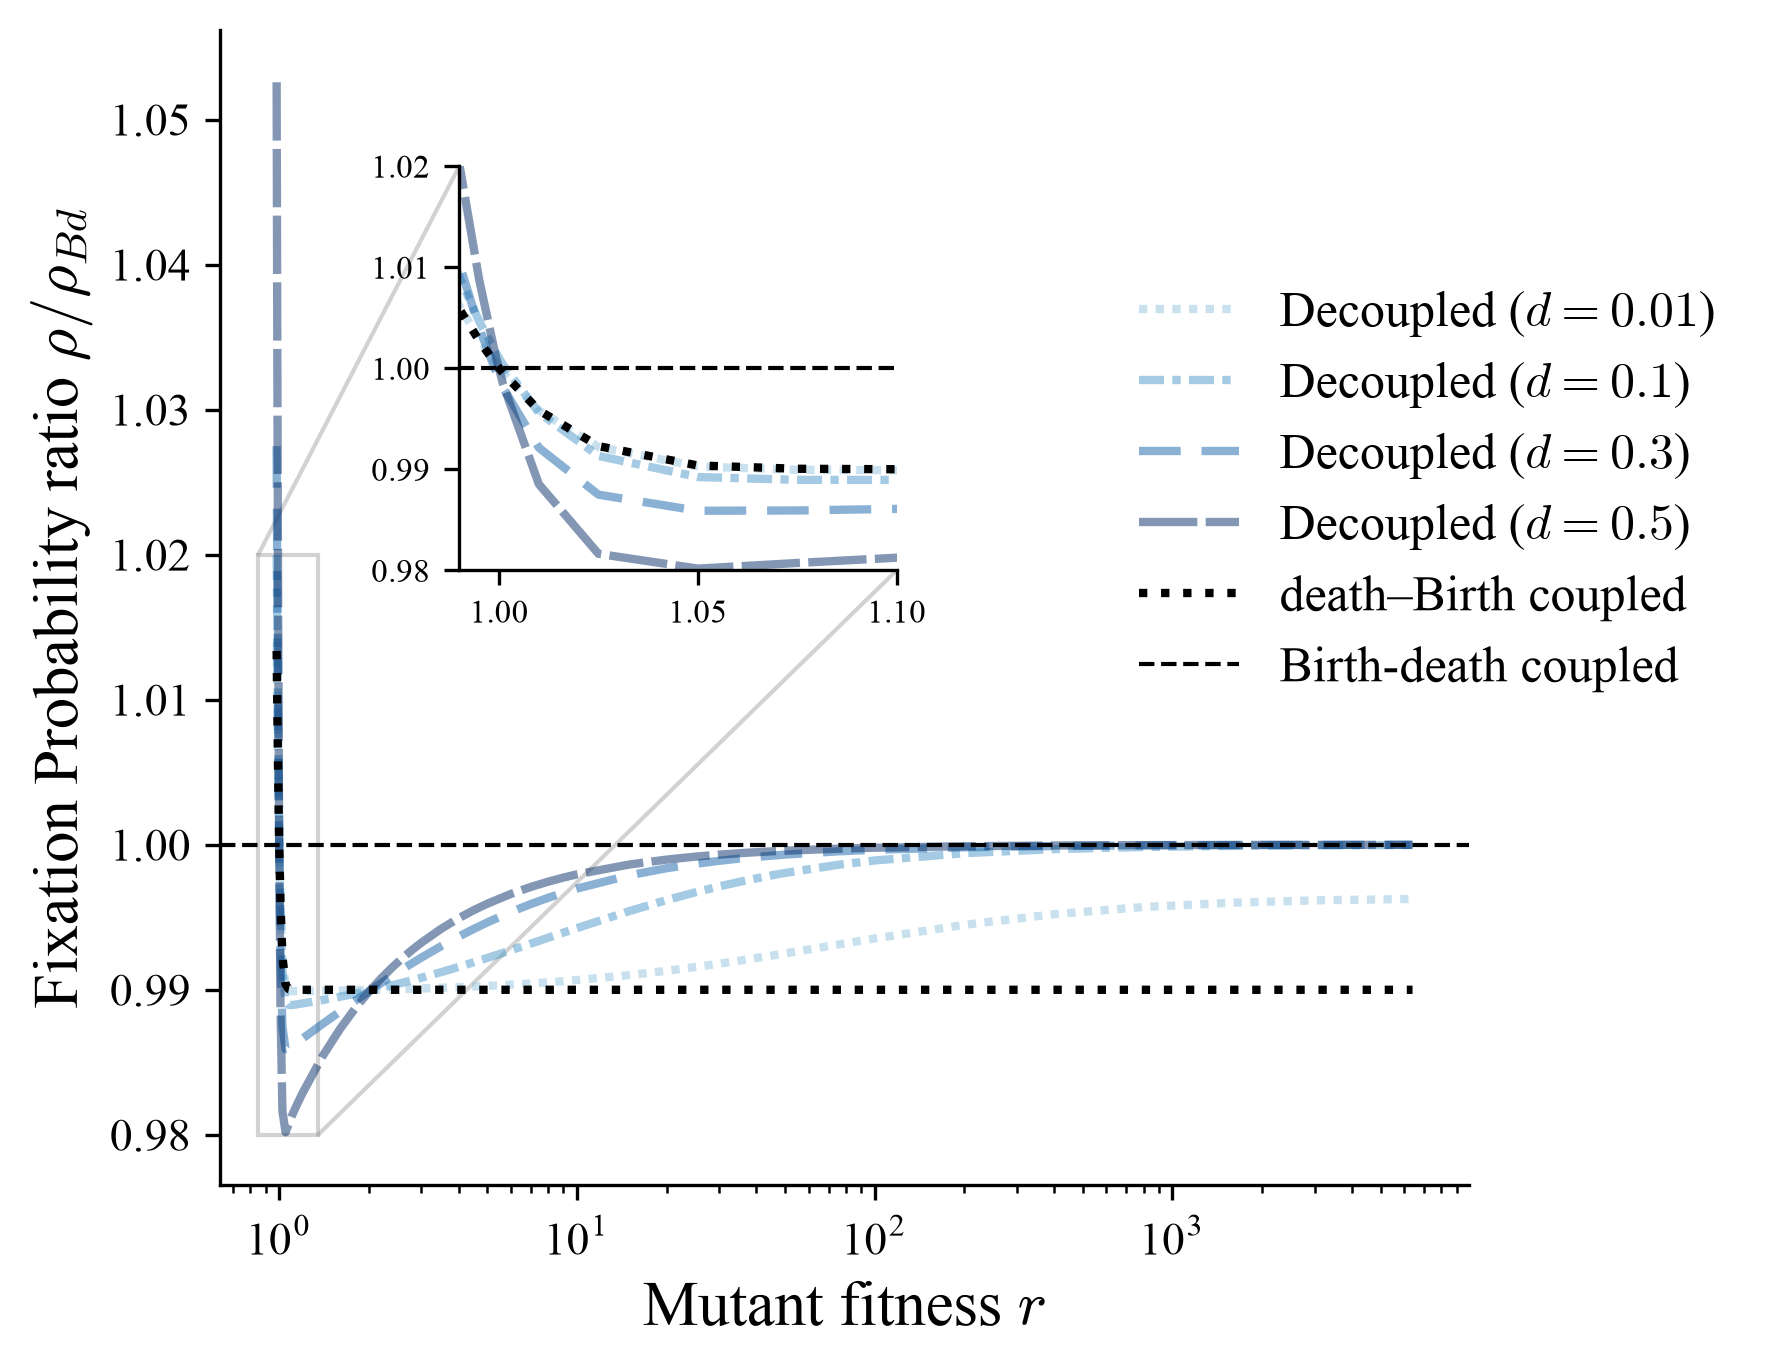

In [6]:
K = 100
plt.figure(figsize=(7,5))
ax = plt.gca()

rs_low = [0.98,0.985,0.99,0.995,0.999,1.001,1.01,1.025,1.05,1.075,1.1,1.125,1.15]
rs_high = [1.2,1.4,1.6,1.8,2.0,2.2,2.4,2.6,2.8,3.0,3.5,4.0,4.5,5.0,6.0,7.0,8.0,9.0,
           10.0,15,20,25,30,35,40,45,50,75,100,200,400,800,1600,3200,6400]

rs_full = rs_low + rs_high

death_rates = [0.01,0.1,0.3,0.5]
linestyles = [
    (0, (1, 1)),
    (0, (3, 1, 1, 1)),
    (0, (5, 2.5)),
    (0, (7, 1)),
    '-'
]
cmap = plt.cm.Blues
colors = cmap(np.linspace(0.4, 1, len(death_rates)))

combined_diffs = {}

for d, color in zip(death_rates, colors):
    with np.load(results_loc / f"well_mixed_extended_d{d}.npz") as data:
        if not np.array_equal(data["rs"], rs_full):
            raise ValueError(f"Unexpected fitness grid for d={d}")
        wm_low = data["probabilities"][:len(rs_low)]
        wm_high = data["probabilities"][len(rs_low):]

    bd_low = [(1-1/r)/(1-1/r**K) if r!=1 else 1/K for r in rs_low]
    bd_high = [(1-1/r)/(1-1/r**K) if r!=1 else 1/K for r in rs_high]

    diff_low = [dec/db for dec, db in zip(wm_low, bd_low)]
    diff_high = [dec/db for dec, db in zip(wm_high, bd_high)]
    diff_full = diff_low + diff_high

    combined_diffs[d] = diff_full

    ax.plot(
        rs_full,
        diff_full,
        color=color,
        linewidth=2,
        linestyle=linestyles[death_rates.index(d)],
        label=rf"Decoupled ($d={d}$)",
        alpha=0.5
    )

db_ref_full = [((1-1/K)*(1-1/r)/(1-1/r**(K-1)))/((1-1/r)/(1-1/r**K)) if r!=1 else 1 for r in rs_full]
ax.plot(
    rs_full,
    db_ref_full,
    color='black',
    linestyle=':',
    linewidth=2,
    label="death–Birth coupled"
)

ax.axhline(
    1,
    color='black',
    linewidth=1,
    linestyle='--',
    label='Birth-death coupled'
)
ax.set_xlabel(r"Mutant fitness $r$", fontsize=15)
ax.set_ylabel(r"Fixation Probability ratio $\rho/\rho_{Bd}$", fontsize=15)
ax.legend(
    loc='center left',
    bbox_to_anchor=(0.7, 0.6),
    frameon=False,
    fontsize=12
)
ax.tick_params(axis='both', labelsize=11)
ax.set_xscale('log')

axins = inset_axes(ax, width="35%", height="35%", loc='upper left',
                    bbox_to_anchor=(0.175, -0.1, 1, 1),
                    bbox_transform=ax.transAxes)

for d, color in zip(death_rates, colors):
    axins.plot(rs_full, combined_diffs[d], color=color, linewidth=2,
               linestyle=linestyles[death_rates.index(d)], alpha=0.5)

axins.plot(rs_full, db_ref_full, color='black', linestyle=':', linewidth=2)
axins.axhline(1, color='black', linewidth=1, linestyle='--')

axins.set_xlim(0.99, 1.1)
axins.set_ylim(0.98, 1.02)
axins.tick_params(axis='both', labelsize=8)

rect_x0, rect_y0 = 0.85, 0.98
rect_width, rect_height = 0.5, 0.04
alpha_val = 0.35

rect = patches.Rectangle(
    (rect_x0, rect_y0), rect_width, rect_height,
    linewidth=1, edgecolor='0.5', facecolor='none',alpha=alpha_val
)
ax.add_patch(rect)

con1 = ConnectionPatch(
    xyA=(rect_x0, rect_y0 + rect_height), coordsA=ax.transData,
    xyB=(0, 1), coordsB=axins.transAxes,
    color='0.5', linewidth=1, alpha=alpha_val
)

con2 = ConnectionPatch(
    xyA=(rect_x0 + rect_width, rect_y0), coordsA=ax.transData,
    xyB=(1, 0), coordsB=axins.transAxes,
    color='0.5', linewidth=1, alpha=alpha_val
)

ax.add_artist(con1)
ax.add_artist(con2)

plt.subplots_adjust(right=0.72)
plt.savefig(
    "well_mixed_takeover_ratios_from_bd_coupled_extended_down.pdf",
    dpi=300,
    bbox_inches='tight'
)
plt.show()
